In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
PROCESSED_FILE = PROJECT_ROOT / "data" / "processed" / "train_FD001_with_rul.csv"

df = pd.read_csv(PROCESSED_FILE)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (20631, 28)


In [3]:
feature_columns = [
    "op_setting_1",
    "op_setting_2",
    "op_setting_3"
]

sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

feature_columns += sensor_columns

target_column = "RUL"

print("Number of features:", len(feature_columns))
print("Target:", target_column)

Number of features: 24
Target: RUL


In [4]:
X = df[feature_columns]
y = df[target_column]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (20631, 24)
Target shape: (20631,)


In [5]:
train_engine_ids = df["unit_id"].unique()[:80]
validation_engine_ids = df["unit_id"].unique()[80:]

train_data = df[df["unit_id"].isin(train_engine_ids)]
validation_data = df[df["unit_id"].isin(validation_engine_ids)]

X_train = train_data[feature_columns]
y_train = train_data[target_column]

X_val = validation_data[feature_columns]
y_val = validation_data[target_column]

print("Training engines:", len(train_engine_ids))
print("Validation engines:", len(validation_engine_ids))

print("Training samples:", len(train_data))
print("Validation samples:", len(validation_data))

Training engines: 80
Validation engines: 20
Training samples: 16138
Validation samples: 4493


In [6]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_val)

print("Model training completed!")

Model training completed!


In [7]:
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print(f"MAE: {mae:.2f} cycles")
print(f"RMSE: {rmse:.2f} cycles")

MAE: 36.47 cycles
RMSE: 51.21 cycles


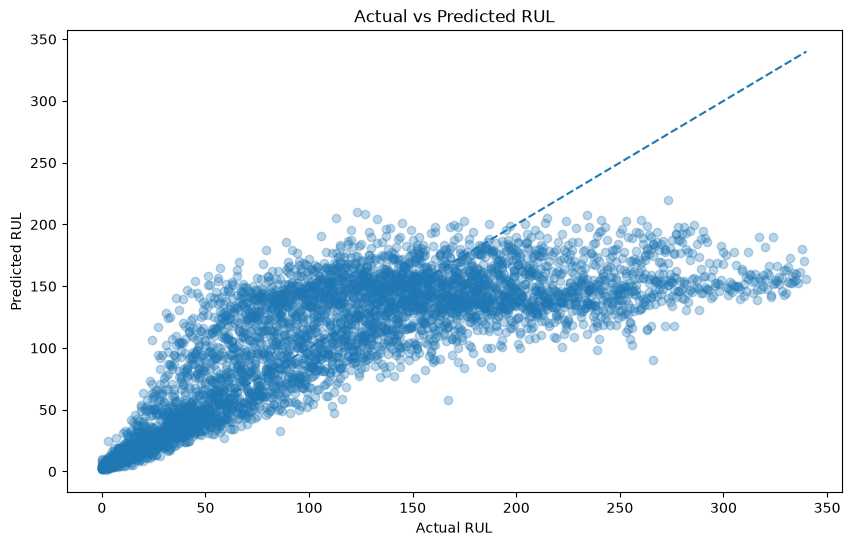

In [8]:
plt.figure(figsize=(10, 6))

plt.scatter(y_val, y_pred, alpha=0.3)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    linestyle="--"
)

plt.show()

In [9]:
results = validation_data[["unit_id", "cycle", "RUL"]].copy()

results["predicted_RUL"] = y_pred

results["error"] = results["predicted_RUL"] - results["RUL"]

results["absolute_error"] = results["error"].abs()

results.head()

,unit_id,cycle,RUL,predicted_RUL,error,absolute_error
16138,81,1,239,150.344020,-88.655980,88.655980
16139,81,2,238,128.496917,-109.503083,109.503083
16140,81,3,237,155.339574,-81.660426,81.660426
16141,81,4,236,149.605660,-86.394340,86.394340
16142,81,5,235,146.580953,-88.419047,88.419047


In [10]:
worst_predictions = results.sort_values(
    "absolute_error",
    ascending=False
)

worst_predictions.head(10)

,unit_id,cycle,RUL,predicted_RUL,error,absolute_error
18526,92,12,329,143.012721,-185.987279,185.987279
18525,92,11,330,144.835264,-185.164736,185.164736
18515,92,1,340,155.467421,-184.532579,184.532579
18519,92,5,336,152.728356,-183.271644,183.271644
18527,92,13,328,146.501890,-181.498110,181.498110
18532,92,18,323,141.653079,-181.346921,181.346921
18522,92,8,333,152.433920,-180.566080,180.566080
19564,96,13,323,142.766526,-180.233474,180.233474
19552,96,1,335,155.220621,-179.779379,179.779379
18521,92,7,334,154.553098,-179.446902,179.446902


In [11]:
engine_errors = (
    results
    .groupby("unit_id")["absolute_error"]
    .mean()
    .sort_values(ascending=False)
)

print("Average error by engine:")
print(engine_errors.head(10))

Average error by engine:
unit_id
92    65.426964
90    57.020862
96    55.058539
84    48.150906
86    44.367712
93    40.203087
94    38.988796
98    38.430463
83    37.871118
99    33.821313
Name: absolute_error, dtype: float64


In [12]:
sensor_variance = (
    train_data[sensor_columns]
    .var()
    .sort_values()
)

print("Sensor variance:")
print(sensor_variance)

Sensor variance:
sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.926049e-34
sensor_5     1.262256e-29
sensor_6     2.009116e-06
sensor_15    1.407722e-03
sensor_8     5.127680e-03
sensor_13    5.271300e-03
sensor_21    1.179516e-02
sensor_20    3.277651e-02
sensor_11    7.151443e-02
sensor_2     2.507116e-01
sensor_12    5.450164e-01
sensor_7     7.884503e-01
sensor_17    2.399496e+00
sensor_3     3.757641e+01
sensor_4     8.058784e+01
sensor_14    3.893261e+02
sensor_9     5.189904e+02
dtype: float64


In [13]:
low_variance_sensors = sensor_variance[
    sensor_variance < 1e-5
].index.tolist()

print("Low-variance sensors:")
print(low_variance_sensors)

print("Number of low-variance sensors:", len(low_variance_sensors))

Low-variance sensors:
['sensor_1', 'sensor_10', 'sensor_19', 'sensor_18', 'sensor_16', 'sensor_5', 'sensor_6']
Number of low-variance sensors: 7


In [14]:
useful_sensors = [
    sensor for sensor in sensor_columns
    if sensor not in low_variance_sensors
]

clean_features = [
    "op_setting_1",
    "op_setting_2",
    "op_setting_3"
] + useful_sensors

print("Original features:", len(feature_columns))
print("Useful features:", len(clean_features))
print("Removed sensors:", low_variance_sensors)

Original features: 24
Useful features: 17
Removed sensors: ['sensor_1', 'sensor_10', 'sensor_19', 'sensor_18', 'sensor_16', 'sensor_5', 'sensor_6']


In [15]:
X_train_clean = train_data[clean_features]
X_val_clean = validation_data[clean_features]

model_clean = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

model_clean.fit(X_train_clean, y_train)

y_pred_clean = model_clean.predict(X_val_clean)

print("Improved model training completed!")

Improved model training completed!


In [16]:
mae_clean = mean_absolute_error(y_val, y_pred_clean)
rmse_clean = np.sqrt(mean_squared_error(y_val, y_pred_clean))

print(f"Improved MAE: {mae_clean:.2f} cycles")
print(f"Improved RMSE: {rmse_clean:.2f} cycles")

Improved MAE: 36.44 cycles
Improved RMSE: 51.19 cycles


In [17]:
rolling_features = df.copy()

for sensor in useful_sensors:
    rolling_features[f"{sensor}_rolling_mean_5"] = (
        rolling_features
        .groupby("unit_id")[sensor]
        .transform(lambda x: x.rolling(window=5, min_periods=1).mean())
    )

print("Rolling features created!")
print("New dataset shape:", rolling_features.shape)

Rolling features created!
New dataset shape: (20631, 42)


In [18]:
rolling_feature_columns = clean_features + [
    f"{sensor}_rolling_mean_5"
    for sensor in useful_sensors
]

rolling_train = rolling_features[
    rolling_features["unit_id"].isin(train_engine_ids)
]

rolling_val = rolling_features[
    rolling_features["unit_id"].isin(validation_engine_ids)
]

X_train_rolling = rolling_train[rolling_feature_columns]
y_train_rolling = rolling_train[target_column]

X_val_rolling = rolling_val[rolling_feature_columns]
y_val_rolling = rolling_val[target_column]

print("Number of features:", len(rolling_feature_columns))
print("Training samples:", len(rolling_train))
print("Validation samples:", len(rolling_val))

Number of features: 31
Training samples: 16138
Validation samples: 4493


In [19]:
model_rolling = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

model_rolling.fit(X_train_rolling, y_train_rolling)

y_pred_rolling = model_rolling.predict(X_val_rolling)

print("Time-series feature model training completed!")

Time-series feature model training completed!


In [20]:
mae_rolling = mean_absolute_error(y_val_rolling, y_pred_rolling)
rmse_rolling = np.sqrt(mean_squared_error(y_val_rolling, y_pred_rolling))

print(f"Time-series MAE: {mae_rolling:.2f} cycles")
print(f"Time-series RMSE: {rmse_rolling:.2f} cycles")

Time-series MAE: 36.04 cycles
Time-series RMSE: 51.30 cycles


In [21]:
experiment_results = pd.DataFrame({
    "Model": [
        "Random Forest Baseline",
        "Random Forest + Low-Variance Removal",
        "Random Forest + Rolling Features"
    ],
    "MAE": [
        mae,
        mae_clean,
        mae_rolling
    ],
    "RMSE": [
        rmse,
        rmse_clean,
        rmse_rolling
    ]
})

experiment_results

,Model,MAE,RMSE
0,Random Forest Baseline,36.465599,51.208184
1,Random Forest + Low-Variance Removal,36.441915,51.185722
2,Random Forest + Rolling Features,36.041218,51.301535


In [22]:
RESULTS_FILE = PROJECT_ROOT / "data" / "processed" / "rul_model_comparison.csv"

experiment_results.to_csv(
    RESULTS_FILE,
    index=False
)

print(f"Experiment results saved to: {RESULTS_FILE}")

Experiment results saved to: /home/ajinkyasingh/Documents/forgemind/data/processed/rul_model_comparison.csv


In [23]:
RUL_CAP = 125

df_capped = df.copy()

df_capped["RUL_capped"] = df_capped["RUL"].clip(
    upper=RUL_CAP
)

print("Original maximum RUL:", df["RUL"].max())
print("Capped maximum RUL:", df_capped["RUL_capped"].max())
print("RUL cap:", RUL_CAP)

Original maximum RUL: 361
Capped maximum RUL: 125
RUL cap: 125


In [24]:
capped_train = df_capped[
    df_capped["unit_id"].isin(train_engine_ids)
]

capped_val = df_capped[
    df_capped["unit_id"].isin(validation_engine_ids)
]

X_train_capped = capped_train[clean_features]
y_train_capped = capped_train["RUL_capped"]

X_val_capped = capped_val[clean_features]
y_val_capped = capped_val["RUL_capped"]

print("Training samples:", len(capped_train))
print("Validation samples:", len(capped_val))
print("Training target maximum:", y_train_capped.max())
print("Validation target maximum:", y_val_capped.max())

Training samples: 16138
Validation samples: 4493
Training target maximum: 125
Validation target maximum: 125


In [25]:
model_capped = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

model_capped.fit(
    X_train_capped,
    y_train_capped
)

y_pred_capped = model_capped.predict(X_val_capped)

print("Capped-RUL model training completed!")

Capped-RUL model training completed!


In [26]:
mae_capped = mean_absolute_error(
    y_val_capped,
    y_pred_capped
)

rmse_capped = np.sqrt(
    mean_squared_error(
        y_val_capped,
        y_pred_capped
    )
)

print(f"Capped-RUL MAE: {mae_capped:.2f} cycles")
print(f"Capped-RUL RMSE: {rmse_capped:.2f} cycles")

Capped-RUL MAE: 14.22 cycles
Capped-RUL RMSE: 19.05 cycles


In [27]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [28]:
mae_capped = mean_absolute_error(
    y_val_capped,
    y_pred_capped
)

rmse_capped = np.sqrt(
    mean_squared_error(
        y_val_capped,
        y_pred_capped
    )
)

print(f"Capped-RUL MAE: {mae_capped:.2f} cycles")
print(f"Capped-RUL RMSE: {rmse_capped:.2f} cycles")

Capped-RUL MAE: 14.22 cycles
Capped-RUL RMSE: 19.05 cycles


In [29]:
experiment_results = pd.DataFrame({
    "Model": [
        "Random Forest Baseline",
        "Random Forest + Low-Variance Removal",
        "Random Forest + Rolling Features",
        "Random Forest + Capped RUL"
    ],
    "MAE": [
        mae,
        mae_clean,
        mae_rolling,
        mae_capped
    ],
    "RMSE": [
        rmse,
        rmse_clean,
        rmse_rolling,
        rmse_capped
    ]
})

experiment_results

,Model,MAE,RMSE
0,Random Forest Baseline,36.465599,51.208184
1,Random Forest + Low-Variance Removal,36.441915,51.185722
2,Random Forest + Rolling Features,36.041218,51.301535
3,Random Forest + Capped RUL,14.221173,19.052641


In [30]:
experiment_results = pd.DataFrame({
    "Model": [
        "Random Forest Baseline",
        "Random Forest + Low-Variance Removal",
        "Random Forest + Rolling Features",
        "Random Forest + Capped RUL"
    ],
    "MAE": [
        mae,
        mae_clean,
        mae_rolling,
        mae_capped
    ],
    "RMSE": [
        rmse,
        rmse_clean,
        rmse_rolling,
        rmse_capped
    ]
})

experiment_results

,Model,MAE,RMSE
0,Random Forest Baseline,36.465599,51.208184
1,Random Forest + Low-Variance Removal,36.441915,51.185722
2,Random Forest + Rolling Features,36.041218,51.301535
3,Random Forest + Capped RUL,14.221173,19.052641


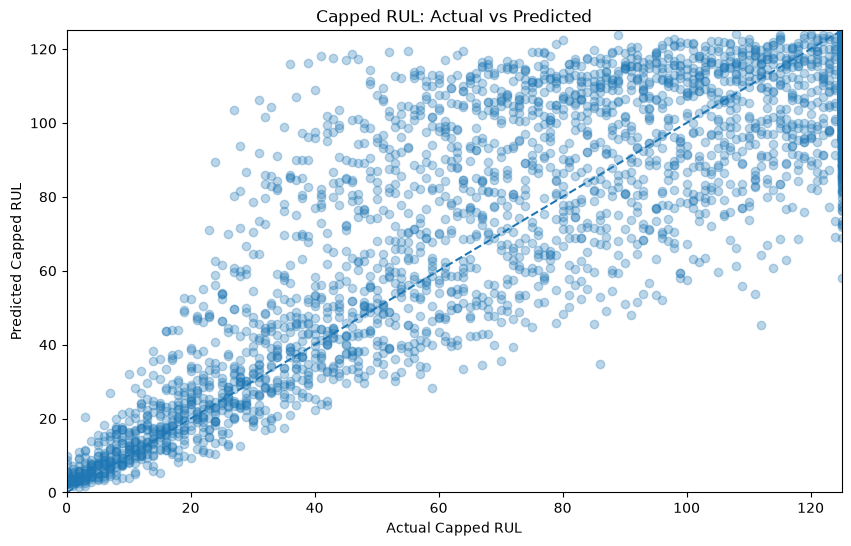

In [31]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_val_capped,
    y_pred_capped,
    alpha=0.3
)

plt.xlabel("Actual Capped RUL")
plt.ylabel("Predicted Capped RUL")
plt.title("Capped RUL: Actual vs Predicted")

plt.plot(
    [0, RUL_CAP],
    [0, RUL_CAP],
    linestyle="--"
)

plt.xlim(0, RUL_CAP)
plt.ylim(0, RUL_CAP)

plt.show()

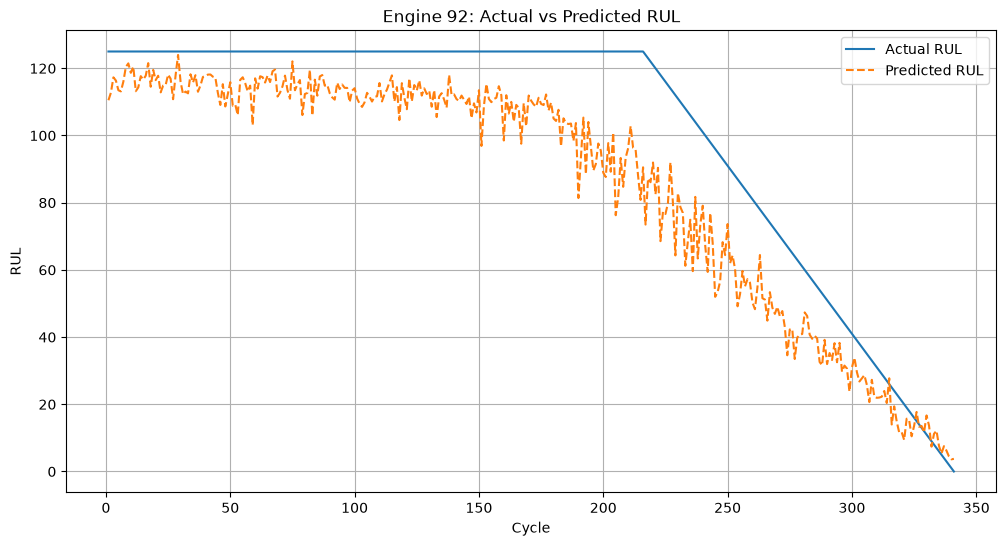

In [32]:
engine_id = 92

engine_data = capped_val[
    capped_val["unit_id"] == engine_id
].copy()

engine_X = engine_data[clean_features]

engine_predictions = model_capped.predict(engine_X)

plt.figure(figsize=(12, 6))

plt.plot(
    engine_data["cycle"],
    engine_data["RUL_capped"],
    label="Actual RUL"
)

plt.plot(
    engine_data["cycle"],
    engine_predictions,
    linestyle="--",
    label="Predicted RUL"
)

plt.xlabel("Cycle")
plt.ylabel("RUL")
plt.title(f"Engine {engine_id}: Actual vs Predicted RUL")

plt.legend()
plt.grid(True)

plt.show()

In [33]:
import joblib

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

MODEL_FILE = MODEL_DIR / "rul_random_forest_capped.joblib"

joblib.dump(
    model_capped,
    MODEL_FILE
)

print(f"Model saved to: {MODEL_FILE}")

Model saved to: /home/ajinkyasingh/Documents/forgemind/models/rul_random_forest_capped.joblib


In [34]:
import json

model_metadata = {
    "model_type": "RandomForestRegressor",
    "target": "RUL_capped",
    "rul_cap": RUL_CAP,
    "n_estimators": 300,
    "max_depth": 15,
    "random_state": 42,
    "features": clean_features,
    "mae": float(mae_capped),
    "rmse": float(rmse_capped)
}

METADATA_FILE = MODEL_DIR / "rul_model_metadata.json"

with open(METADATA_FILE, "w") as f:
    json.dump(model_metadata, f, indent=4)

print(f"Metadata saved to: {METADATA_FILE}")

Metadata saved to: /home/ajinkyasingh/Documents/forgemind/models/rul_model_metadata.json


In [35]:
loaded_model = joblib.load(MODEL_FILE)

sample_prediction = loaded_model.predict(
    X_val_capped.iloc[:5]
)

print("Saved model loaded successfully!")
print("Sample predictions:")
print(sample_prediction)

Saved model loaded successfully!
Sample predictions:
[110.93258343 107.55747053 109.95073736 111.92300399 103.39979453]
